# Why pace displaced spin

**The question, given the season contrasts.** Pace's share of legal balls rose in every phase in 2024, by 6 points in the powerplay, 10 in the middle and 8 at the death, and no mechanism has been given. A league's spin share can fall for three reasons a team decides: it picks fewer spinners (selection), it leaves the spinners it picked unused (deployment), or it gives each spinner fewer balls (workload). This notebook separates them.

**What this notebook does.** The spin share of legal balls is an exact identity in four factors: spinners named per bowling innings (from the twelve on each roster), the share of named spinners who bowled, spin balls per spinner who bowled, and legal balls per innings. The season change in spin share is attributed to the four by Shapley values (every ordering, increments averaged) under the match cluster bootstrap, for the whole innings and per phase; the phase versions use that phase's spin and legal balls with the same selection and deployment counts, so they separate "picked fewer spinners" from "used them differently within the innings". Then the selection picture by team.

**How to read this notebook.** A *spinner* is a bowler whose legal balls across the two seasons are mostly spin, at a 60-ball floor (41 of the 117 bowlers at the floor). Contributions are in percentage points of spin share and sum to the observed change; `identity_max_abs_error` should be at floating-point precision. Two seasons, so this is a step, not a trend, and it describes decisions rather than their reasons.

**Numbers in the text.** Quoted from the run of 13 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Code lives in `scripts/spin_displacement/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from spin_displacement import selection_or_usage as sou

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "spin_displacement"
SEED = settings.seed("global")
N_ITER = settings.n_resamples
MIN_BALLS = int(settings.section("spin_displacement")["spinner_min_balls"])
PRODUCER = "spin_displacement.ipynb"
YEARS = (settings.earlier_season, settings.later_season)
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}  spinner floor={MIN_BALLS}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000  spinner floor=60


## Data

The cleaned frame and the match rosters (built in `exploration.ipynb`).

In [2]:
df = scb.load_cleaned_dataset(str(settings.data_path("cleaned_dataset")))
rosters = pd.read_parquet(settings.data_path("match_rosters"))
print(f"balls={len(df):,}  matches={df['p_match'].nunique()}  roster rows={len(rosters)}")
EXTRA = {"n_resamples": N_ITER, "spinner_min_balls": MIN_BALLS}

balls=34,967  matches=145  roster rows=3467


## Who is a spinner, and the bowling-innings table

Each bowler's legal balls and spin share; then per bowling innings the named spinners, the spinners who bowled, and spin and legal balls per phase. Found: 2.69 spinners named per bowling innings in 2023 and 2.40 in 2024; 2.39 and 1.93 bowled; 48 spin balls per innings became 38.

In [3]:
spinners = sou.classify_spinners(df, MIN_BALLS)
results_io.write_table(spinners, settings, ANALYSIS, "spinner_classification", SEED, PRODUCER, EXTRA)
print("spinners:", int(spinners["is_spinner"].sum()), "of", len(spinners), "bowlers at the floor:", int((spinners["legal"] >= MIN_BALLS).sum()))
innings = sou.bowling_innings_table(df, rosters, spinners, settings)
results_io.write_table(innings, settings, ANALYSIS, "bowling_innings", SEED, PRODUCER, EXTRA)
print("unmatched roster innings (named filled from used):", int(innings["spinners_named"].isna().sum()))
innings.groupby("season")[["spinners_named", "spinners_used", "spin_all", "legal_all"]].mean().round(3)

spinners: 41 of 183 bowlers at the floor: 117
unmatched roster innings (named filled from used): 0


,spinners_named,spinners_used,spin_all,legal_all
season,,,,
2023,2.687,2.388,48.449,116.585
2024,2.401,1.930,38.479,114.782


## Selection, deployment or workload

Per phase: the spin share per season, its change, and each factor's contribution with interval, P(positive) and share of the change.

In [4]:
table = sou.run_decomposition(innings, settings, SEED, N_ITER)
results_io.write_table(table, settings, ANALYSIS, "spin_share_decomposition", SEED, PRODUCER, EXTRA)
print(table.loc[table["factor"] == "spin_share_change", ["phase", "contribution_points", "ci_low", "ci_high", "identity_max_abs_error"]].to_string(index=False))
table.round(4)

    phase  contribution_points     ci_low   ci_high  identity_max_abs_error
      all            -8.033245 -10.778979 -5.347496            2.498002e-16
powerplay            -6.111803 -10.095544 -2.059751            1.110223e-16
   middle            -9.953882 -14.255860 -5.753883            4.440892e-16
    death            -7.268878 -11.489920 -2.987818            1.387779e-16


,phase,factor,value_2023,value_2024,contribution_points,ci_low,ci_high,p_positive,share_of_change,identity_max_abs_error
0,all,spinners_named_per_innings,2.6871,2.4014,-4.2030,-7.2843,-1.2751,0.0020,0.5232,NaN
1,all,share_of_named_spinners_used,0.8886,0.8035,-3.7647,-6.2213,-1.3262,0.0014,0.4686,NaN
2,all,spin_balls_per_spinner_used,20.2906,19.9416,-0.6499,-2.7939,1.4682,0.2747,0.0809,NaN
3,all,legal_balls_per_innings,116.5850,114.7817,0.5843,-0.1527,1.3651,0.9389,-0.0727,NaN
4,all,spin_share_change,0.4156,0.3352,-8.0332,-10.7790,-5.3475,0.0000,1.0000,0.0
5,powerplay,spinners_named_per_innings,2.6871,2.4014,-1.9199,-3.3268,-0.5702,0.0020,0.3141,NaN
6,powerplay,share_of_named_spinners_used,0.8886,0.8035,-1.7199,-2.8647,-0.6065,0.0014,0.2814,NaN
7,powerplay,spin_balls_per_spinner_used,3.0627,2.6496,-2.4721,-6.2723,1.4673,0.1027,0.4045,NaN
8,powerplay,legal_balls_per_innings,36.0000,36.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,NaN
9,powerplay,spin_share_change,0.2031,0.1420,-6.1118,-10.0955,-2.0598,0.0023,1.0000,0.0


Spin share fell from 41.6% to 33.5% of legal balls, −8.0 points (interval −10.8 to −5.3). Selection and deployment did it in equal measure, and workload did nothing: teams named 0.29 fewer spinners per innings (−4.2 points, interval −7.3 to −1.3, 52% of the change) and left more of the ones they named unbowled, the used share falling from 89% to 80% (−3.8 points, interval −6.2 to −1.3, 47%); balls per spinner who bowled were unchanged at about 20 (−0.6, interval includes zero).

The phases tell where the unused spinner's overs went. In the middle overs, where pace rose most, the fall of −10.0 points is entirely selection (−6.8) and deployment (−6.1), with workload per spinner actually up (+2.3, P 0.87): the spinners who did bowl still bowled their middle overs; there were simply fewer of them. At the death the picture reverses: selection and deployment account for −4.0 of the −7.3 and workload −4.2 (interval −8.3 to −0.1), so the spinners who played were also taken off at the death. The powerplay sits between (−1.9, −1.7 and −2.5).

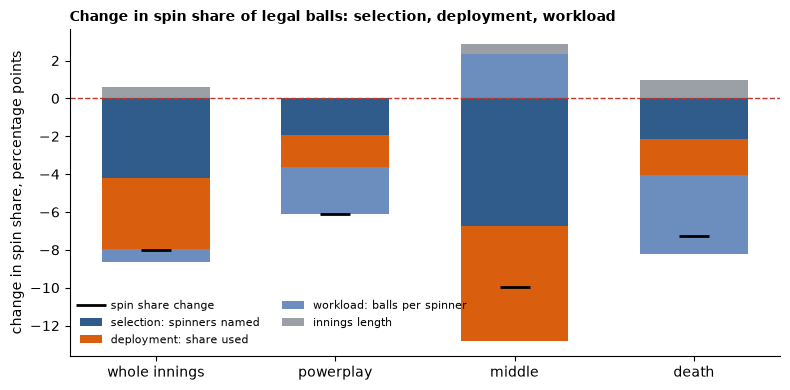

In [5]:
fig = sou.plot_contributions(table, "Change in spin share of legal balls: selection, deployment, workload")
results_io.write_figure(fig, settings, ANALYSIS, "spin_share_contributions", SEED, PRODUCER)
plt.show()

## Selection by team

Named and used spinners per bowling innings and the spin share, by team and season.

In [6]:
by_team = sou.selection_by_team(innings)
results_io.write_table(by_team.reset_index(), settings, ANALYSIS, "selection_by_team", SEED, PRODUCER, EXTRA)
by_team

spinners_named           spinners_used           spin_share          
season                                2023      2024          2023      2024       2023      2024
team                                                                                             
Chennai Super Kings                 2.9375  2.357143        2.6875  1.857143   0.453782  0.314634
Delhi Capitals                    2.428571  1.928571      2.214286  1.928571   0.402636  0.336585
Gujarat Titans                    1.764706      2.25      1.764706      2.25   0.364095  0.446565
Kolkata Knight Riders                  3.0  2.357143           3.0  2.357143   0.555834  0.436548
Lucknow Super Giants              3.071429  2.142857      2.928571       2.0    0.46778  0.362708
Mumbai Indians                         2.0  1.285714           2.0  1.214286   0.366685  0.248293
Punjab Kings                      3.071429       4.0      2.571429  1.928571   0.375077    0.2997
Rajasthan Royals                  2.428571  1.933333      2.357143  1.933333      0.475  0.410544
Royal Challengers Bengaluru       3.142857  2.066667      2.285714       1.8   0.321201   0.27677
Sunrisers Hyderabad               3.285714    3.5625      2.214286    2.0625   0.382678  0.250695

Eight of ten teams named fewer spinners in 2024; Gujarat and Punjab named more, and Punjab is the clearest case of deployment doing the work (4.0 named, 1.9 bowled). Mumbai went furthest on selection (2.0 to 1.3 named) and has the lowest 2024 spin share (25%); Sunrisers kept naming spinners (3.6) but bowled only 2.1 of them and cut its spin share from 38% to 25%; Kolkata and Lucknow cut a spinner each and their spin share by 10 to 12 points. Gujarat is the one side that went the other way, from 1.8 to 2.3 spinners and 36% to 45% spin.

## Squad, eleven or bench: where the missing spinners went

The auction tables add the level above the eleven. Per team and season: spinners carried in the squad (squad members classified from the ball-by-ball; members who never bowled are unclassified and counted separately), the share of squad spend on spinners, spinners named per eleven and used per innings, so the drop can be placed at the squad, the team sheet, or the bench; and each classified spinner's movement between seasons.

In [7]:
from common import auction as auc
from spin_displacement import squad_spinners as squad

auction_table = auc.load_auction(settings.data_path("auction_workbook"))
players = auc.dataset_players(df)
matched, unmatched = auc.match_auction_to_dataset(auction_table, players)
display(auc.match_report(matched))
squads = squad.squad_composition(matched, spinners)
chain = squad.squad_to_eleven(squads, innings)
flow = squad.spinner_flow(matched, spinners, YEARS[0], YEARS[1])
for name, table in (("squad_composition", squads), ("squad_to_eleven", chain), ("spinner_flow", flow)):
    results_io.write_table(table, settings, ANALYSIS, name, SEED, PRODUCER, EXTRA)
display(chain.round(3))
display(squad.flow_summary(flow))
print(squads.groupby("season")[["squad", "spinners", "unclassified", "spend_share_spinners"]].mean().round(3))
flow[flow["movement"] != "retained"].sort_values("movement")

,season,status,rows,matched,match_rate
0,2023,Retained,153,139,0.908497
1,2023,Sold,80,62,0.775
2,2023,Traded,5,5,1.0
3,2023,Unsold,62,18,0.290323
4,2024,Retained,166,155,0.933735
5,2024,Sold,72,53,0.736111
6,2024,Traded,7,7,1.0
7,2024,Unsold,62,19,0.306452


,team,season,squad,spinners,unclassified,spend_share_spinners,spinners_named,spinners_used,named_share_of_squad_spinners
0,Chennai Super Kings,2023,25,4,12,0.284,2.938,2.688,0.734
1,Chennai Super Kings,2024,25,4,10,0.269,2.357,1.857,0.589
2,Delhi Capitals,2023,25,3,13,0.134,2.429,2.214,0.81
3,Delhi Capitals,2024,25,3,12,0.135,1.929,1.929,0.643
4,Gujarat Titans,2023,25,3,13,0.202,1.765,1.765,0.588
5,Gujarat Titans,2024,25,3,10,0.199,2.25,2.250,0.75
6,Kolkata Knight Riders,2023,22,4,7,0.169,3.0,3.000,0.75
7,Kolkata Knight Riders,2024,23,4,10,0.159,2.357,2.357,0.589
8,Lucknow Super Giants,2023,25,5,7,0.153,3.071,2.929,0.614
9,Lucknow Super Giants,2024,25,4,8,0.139,2.143,2.000,0.536


,movement,spinners
0,retained,32
1,bought_by_a_team,3
2,unsold_at_later_auction,2
3,new_to_the_league,2
4,traded,2


        squad  spinners  unclassified  spend_share_spinners
season                                                     
2023     23.8       3.6           9.9                 0.175
2024     24.5       3.8           9.9                 0.164


,player_id,name,status_2023,team_2023,status_2024,team_2024,price_2024_cr,movement
1,25913,Mohammad Nabi,Unsold,Unsold,Sold,Mumbai Indians,1.50,bought_by_a_team
7,232292,Swapnil Singh,Sold,Lucknow Super Giants,Sold,Royal Challengers Bengaluru,0.20,bought_by_a_team
22,784379,Wanindu Hasaranga,Retained,Royal Challengers Bengaluru,Sold,Sunrisers Hyderabad,1.50,bought_by_a_team
20,600498,Aiden Markram,absent,,Retained,Sunrisers Hyderabad,2.60,new_to_the_league
21,719715,Washington Sundar,absent,,Retained,Sunrisers Hyderabad,8.75,new_to_the_league
25,942367,Mayank Dagar,Sold,Sunrisers Hyderabad,Traded,Royal Challengers Bengaluru,1.80,traded
34,1159711,Shahbaz Ahmed,Retained,Royal Challengers Bengaluru,Traded,Sunrisers Hyderabad,2.40,traded
11,326968,Michael Bracewell,absent,,Unsold,Unsold,NaN,unsold_at_later_auction
37,1175423,Hrithik Shokeen,Retained,Mumbai Indians,Unsold,Unsold,NaN,unsold_at_later_auction


Squads did not shed spinners. Teams carried 3.6 classified spinners per squad in 2023 and 3.8 in 2024, spent 17.5% and 16.4% of their auction money on them, and of the 41 spinners 32 were retained, three bought, two traded, two new to the league and two unsold. The drop was made at the team sheet: the share of a squad's spinners named per innings fell from about 0.74 to 0.60, most sharply at Bengaluru (0.79 to 0.52), Mumbai (0.67 to 0.43), Lucknow (0.61 to 0.54) and Kolkata (0.75 to 0.59). Sunrisers carried six spinners and named 3.6 of them; Punjab named all four of its spinners and bowled 1.9. The decision to bowl less spin was taken on match day, not at the auction.

Pace displaced spin by selection and by benching, not by rationing and not by squad building. Teams kept and bought spinners as before, picked about a third of a spinner fewer per eleven, and bowled fewer of the ones they picked, while the spinners who did bowl kept their workload; the middle overs, where the shift was largest, were a change in how many spinners were available, and the death was where the ones available were also taken off. Read beside the bowling-response finding, where spin was the class hit hardest in the powerplay (+4.3 sixes per 100 balls), the team-sheet decision looks like a response to what spin was conceding rather than a fashion.